In [ ]:
!pip -q install yfinance # 데이터셋 yahoo finance에서 주가 관련된 지표 가져오기

In [ ]:
!pip install -q ta  # 기술적 분석 라이브러리: 그 가격으로 RSI, 볼린저 밴드, MACD, Williams %R, 이동평균선을 계산

  Preparing metadata (setup.py) ... done


In [ ]:
import yfinance as yf
import datetime
import time
import tqdm
import random
import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from ta.trend import SMAIndicator, MACD
from ta.volatility import BollingerBands
from ta.momentum import RSIIndicator, WilliamsRIndicator

from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

warnings.filterwarnings("ignore")

In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    DEVICE = torch.device("xpu")
else:
    DEVICE = torch.device("cpu")

print("DEVICE:", DEVICE)

DEVICE: cuda


In [ ]:
TICKER = "^GSPC"
START = "2000-01-01"
SEQ_LENGTH = 60

df = yf.download(
    TICKER,
    start=START,
    interval="1d",
    auto_adjust=True,
    progress=False,
    multi_level_index=False,
)

if df.empty:
    raise ValueError(f"{TICKER} 데이터를 가져오지 못했습니다.")

df = df.sort_index().copy()

print("데이터 크기:", df.shape)
print("처음 날짜:", df.index.min())
print("마지막 날짜:", df.index.max())

데이터 크기: (6729, 5)
처음 날짜: 2000-01-03 00:00:00
마지막 날짜: 2026-10-05 00:00:00


In [ ]:
close = df["Close"]
high = df["High"]
low = df["Low"]

# SMAIndicator(...).sma_indicator()	20일 이동평균 값 생성
df["SMA_20"] = SMAIndicator(close=close, window=20).sma_indicator()

# RSI를 계산하기 위해 ta가 제공하는 RSIIndicator 함수
df["RSI_14"] = RSIIndicator(close=close, window=14).rsi() # RSI 14 거래일

# BollingerBands(...)	볼린저 밴드 계산 객체 생성
bb = BollingerBands(close=close, window=20, window_dev=2)  # 볼린저 밴드 20 거래일, 위 아래 폭 표준편차의 2배

# bb.bollinger_hband()	볼린저 밴드 상단 값 생성
df["BB_upper"] = bb.bollinger_hband()
# bb.bollinger_lband()	볼린저 밴드 하단 값 생성
df["BB_lower"] = bb.bollinger_lband()

# MACD 계산 객체 생성
macd = MACD(close=close, window_slow=26, window_fast=12, window_sign=9)  # 느리게 반응하는 26 거래일, 빠르게 반응하는 12거래일, 신호선의 9거래일
# MACD 값 생성
df["MACD"] = macd.macd()
# MACD 신호선 값 생성
df["MACD_signal"] = macd.macd_signal()

# Williams %R 값 생성
df["Williams_R"] = WilliamsRIndicator(
    high=high,
    low=low,
    close=close,
    lbp=14,
).williams_r()

# display(df.tail()) # 마지막 5행 확인

In [ ]:
# 모델에 보여줄 정보
feature_cols = [
    "Open", "High", "Low", "Close",
    "SMA_20", "RSI_14",
    "BB_upper", "BB_lower",
    "MACD", "MACD_signal", "Williams_R",
]

data = df[feature_cols].dropna().copy()
data.head()

,Open,High,Low,Close,SMA_20,RSI_14,BB_upper,BB_lower,MACD,MACD_signal,Williams_R
Date,,,,,,,,,,,
2000-02-18,1388.260010,1388.589966,1345.319946,1346.089966,1401.609998,32.769237,1444.715586,1358.504409,-14.323704,-9.393564,-99.224006
2000-02-22,1346.089966,1358.109985,1331.880005,1352.170044,1399.141998,34.926772,1447.335236,1350.948760,-16.615657,-10.837983,-81.991629
2000-02-23,1352.170044,1370.109985,1342.439941,1360.689941,1396.674994,37.932595,1447.372588,1345.977400,-17.542344,-12.178855,-74.429817
2000-02-24,1360.689941,1364.800049,1329.880005,1353.430054,1394.141998,36.390098,1448.064261,1340.219736,-18.647605,-13.472605,-79.462772
2000-02-25,1353.430054,1362.140015,1329.150024,1333.359985,1390.881995,32.460317,1450.882717,1330.881272,-20.902072,-14.958498,-96.351854


In [ ]:
print("원본 행 수:", len(df))
print("지표 결측값 제거 후:", len(data))

원본 행 수: 6729
지표 결측값 제거 후: 6696


In [ ]:
# 2026년 8월까지 학습
# 9월 검증
# 10월 테스트
train_data = data.loc[data.index < "2026-09-01"]
val_data = data.loc[
    (data.index >= "2026-09-01") &
    (data.index < "2026-10-01")
]
test_data = data.loc[data.index >= "2026-10-01"]

In [ ]:
print("학습:", train_data.index.min(), "~", train_data.index.max(), len(train_data))
print("검증:", val_data.index.min(), "~", val_data.index.max(), len(val_data))
print("테스트:", test_data.index.min(), "~", test_data.index.max(), len(test_data))

학습: 2000-02-18 00:00:00 ~ 2026-08-31 00:00:00 6672
검증: 2026-09-01 00:00:00 ~ 2026-09-30 00:00:00 21
테스트: 2026-10-01 00:00:00 ~ 2026-10-05 00:00:00 3


In [ ]:
# 스케일 진행

# 입력 열 전체를 변환
x_scaler = StandardScaler()
# Close열 변환, 예측 결과를 원래 가격 단위로 될돌릴 때도 사용
y_scaler = StandardScaler()

# 평균과 표준편차는 학습 기간(8월까지)의 데이터로만 계산
x_scaler.fit(train_data[feature_cols])
y_scaler.fit(train_data[["Close"]])

# 정해진 학습 기간 기준을 전체 날짜에 동일하게 적용
# transform은 핛브 데이터에서 정해 둔 기준을 다른 날짜에도 적용
scaled_X = x_scaler.transform(data[feature_cols]).astype(np.float32)
scaled_y = y_scaler.transform(data[["Close"]]).astype(np.float32)

print("입력 X:", scaled_X.shape)  # feature_cols 11개 지표를 넣음
print("정답 y:", scaled_y.shape)  #

입력 X: (6696, 11)
정답 y: (6696, 1)


In [ ]:
# 연속된 60(SEQ_LENGTH) 거래일을 입력 하나로 묶음
# 시간에 따라 값이 어떻게 변했는지 보기 위해
def make_sequence(features, targets, seq_length):
    X = []
    y = []
    target_indices = []

    for i in range(seq_length, len(features)):
        X.append(features[i - seq_length:i])  # 예측이 직전 거래일 지표(SEQ_LENGTH)
        y.append(targets[i])  # 예측일 증가
        target_indices.append(i)

    return (
        np.array(X, dtype=np.float32),
        np.array(y, dtype=np.float32),
        np.array(target_indices),
    )

X, y, indices = make_sequence(scaled_X, scaled_y, SEQ_LENGTH)

print("X:", X.shape)
print("y:", y.shape)

X: (6636, 60, 11)
y: (6636, 1)


In [ ]:
# 60일(SEQ_LENTGTH)짜리 학습 예시들을 정답 날짜에 따라 학습·검증·테스트로 나누는 코드
target_dates = data.index[indices]

train_mask = target_dates < "2026-09-01"
val_mask = (target_dates >= "2026-09-01") & (target_dates < "2026-10-01")
test_mask = target_dates >= "2026-10-01"

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("학습:", X_train.shape, y_train.shape)
print("검증:", X_val.shape, y_val.shape)
print("테스트:", X_test.shape, y_test.shape)

학습: (6612, 60, 11) (6612, 1)
검증: (21, 60, 11) (21, 1)
테스트: (3, 60, 11) (3, 1)


In [ ]:
class PowerDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

In [ ]:
BATCH_SIZE = 64

train_loader = DataLoader(
    PowerDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader = DataLoader(
    PowerDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

test_loader = DataLoader(
    PowerDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [ ]:
xb, yb = next(iter(train_loader))

print("입력:", xb.shape)
print("정답:", yb.shape)

입력: torch.Size([64, 60, 11])
정답: torch.Size([64, 1])


In [ ]:
# LSTM모델 생성
class PowerLSTM(nn.Module):
    def __init__(self, input_size=len(feature_cols), hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last_hidden = out[:, -1, :]
        prediction = self.fc(last_hidden)
        return prediction

In [ ]:
model = PowerLSTM(input_size=len(feature_cols)).to(DEVICE)
model

PowerLSTM(
  (lstm): LSTM(11, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

In [ ]:
# 모델을 평가 모드로 변환
model.eval()

with torch.no_grad():
    sample_x = xb[:4].to(DEVICE)  # 기울기 기록 X
    out, (h_n, c_n) = model.lstm(sample_x)

print("입력: ", sample_x.shape)
print("out: ", out.shape)
print("h_n(hidden state): ", h_n.shape)
print("c_n: ", c_n.shape)

입력:  torch.Size([4, 60, 11])
out:  torch.Size([4, 60, 64])
h_n(hidden state):  torch.Size([2, 4, 64])
c_n:  torch.Size([2, 4, 64])


In [ ]:
def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            pred = model(xb)
            loss = criterion(pred, yb)

            batch_size = xb.size(0)
            total_loss += loss.item() * batch_size
            total_count += batch_size

    return total_loss / total_count

In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

MAX_EPOCHS = 50
PATIENCE = 8
CLIP_NORM = 1.0

In [ ]:
best_val_loss = float("inf")
best_state = None
wait = 0

train_history = []
val_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    train_count = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)
        loss = criterion(pred, yb)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=CLIP_NORM
        )
        optimizer.step()

        batch_size = xb.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count
    val_loss = evaluate_loss(model, val_loader, criterion, DEVICE)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train {train_loss:.6f} | "
        f"Valid {val_loss:.6f}"
    )

    if wait >= PATIENCE:
        print("Early Stopping")
        break

Epoch 01 | Train 0.123681 | Valid 0.016495
Epoch 02 | Train 0.002583 | Valid 0.016074
Epoch 03 | Train 0.002365 | Valid 0.004803
Epoch 04 | Train 0.001961 | Valid 0.001481
Epoch 05 | Train 0.001608 | Valid 0.003402
Epoch 06 | Train 0.001667 | Valid 0.005618
Epoch 07 | Train 0.001421 | Valid 0.001450
Epoch 08 | Train 0.001439 | Valid 0.005300
Epoch 09 | Train 0.001585 | Valid 0.002645
Epoch 10 | Train 0.001371 | Valid 0.009738
Epoch 11 | Train 0.001296 | Valid 0.005090
Epoch 12 | Train 0.001154 | Valid 0.001014
Epoch 13 | Train 0.001126 | Valid 0.002045
Epoch 14 | Train 0.001524 | Valid 0.006891
Epoch 15 | Train 0.001380 | Valid 0.002046
Epoch 16 | Train 0.001087 | Valid 0.003563
Epoch 17 | Train 0.001006 | Valid 0.001006
Epoch 18 | Train 0.001207 | Valid 0.038151
Epoch 19 | Train 0.001456 | Valid 0.008933
Epoch 20 | Train 0.001018 | Valid 0.001572
Epoch 21 | Train 0.001106 | Valid 0.000939
Epoch 22 | Train 0.000963 | Valid 0.002142
Epoch 23 | Train 0.001218 | Valid 0.000966
Epoch 24 | 

In [ ]:
if best_state is not None:
    model.load_state_dict(best_state)

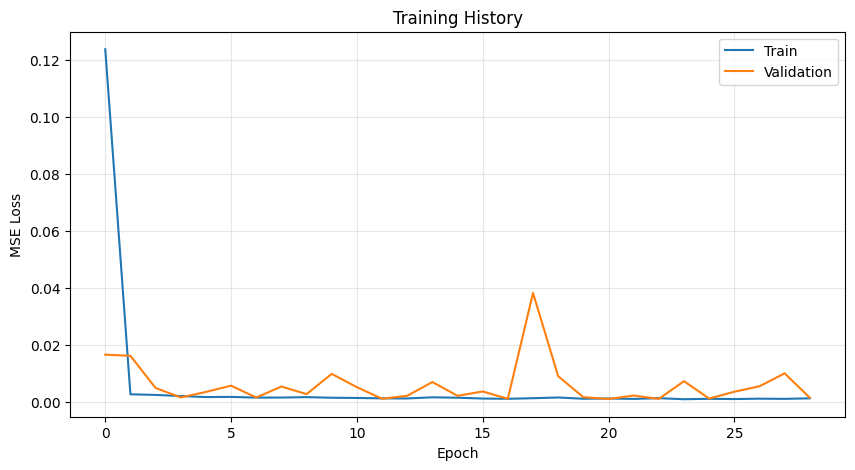

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(train_history, label="Train")
plt.plot(val_history, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
def predict(model, loader, device):
    model.eval()
    preds = []
    trues = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            pred = model(xb)
            preds.append(pred.cpu().numpy())
            trues.append(yb.cpu().numpy())

    return np.vstack(preds), np.vstack(trues)

In [ ]:
pred_scaled, true_scaled = predict(model, test_loader, DEVICE)

pred = y_scaler.inverse_transform(pred_scaled).ravel()
true = y_scaler.inverse_transform(true_scaled).ravel()

print("예측 개수:", len(pred))
print("실제값:", true[:5])
print("예측값:", pred[:5])

예측 개수: 3
실제값: [7666.4507 7722.72   7761.8506]
예측값: [7661.1167 7664.47   7692.1753]


In [ ]:
rmse = root_mean_squared_error(true, pred)
mae = mean_absolute_error(true, pred)

test_indices = indices[test_mask]
baseline_pred = data["Close"].to_numpy()[test_indices - 1]

baseline_rmse = root_mean_squared_error(true, baseline_pred)
baseline_mae = mean_absolute_error(true, baseline_pred)

print(f"Persistence RMSE: {baseline_rmse:.4f}")
print(f"Persistence MAE : {baseline_mae:.4f}")
print(f"LSTM RMSE       : {rmse:.4f}")
print(f"LSTM MAE        : {mae:.4f}")

Persistence RMSE: 40.4962
Persistence MAE : 36.7703
LSTM RMSE       : 52.5235
LSTM MAE        : 44.4198


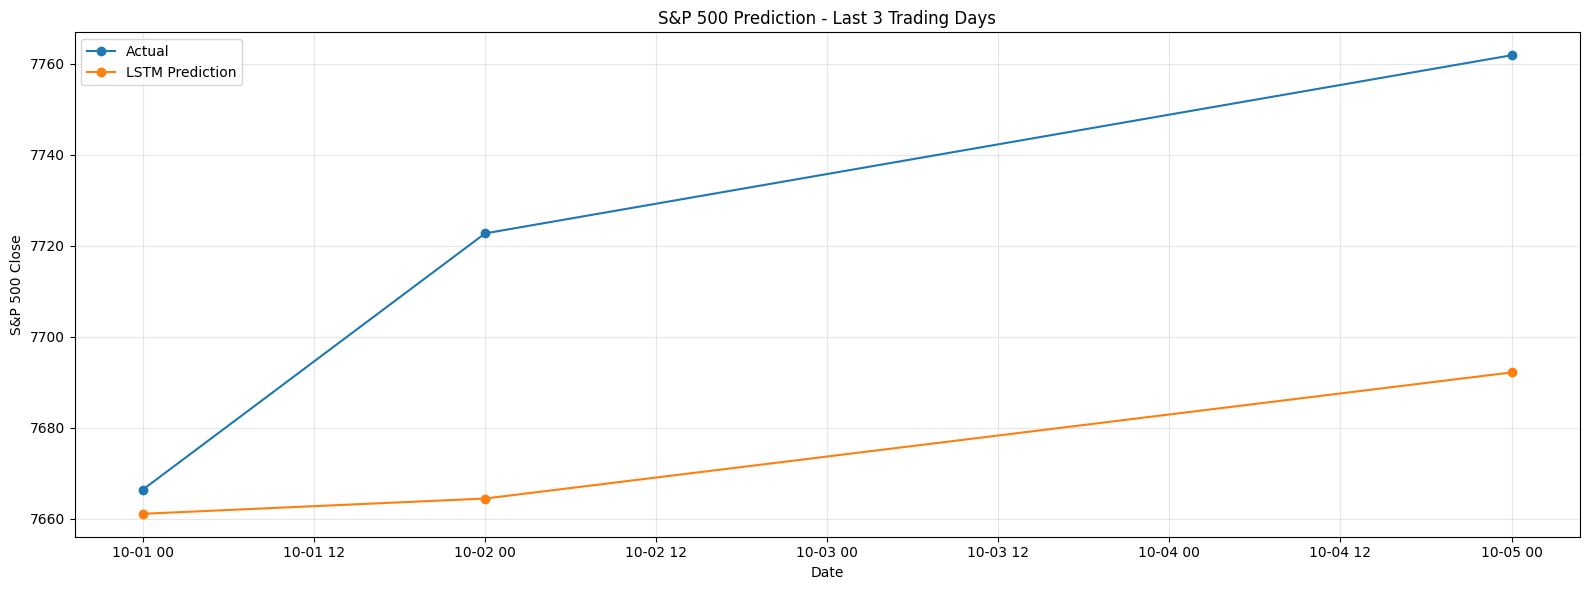

In [ ]:
test_dates = data.index[indices[test_mask]]
N_VIEW = min(200, len(test_dates))

plt.figure(figsize=(16, 6))

plt.plot(
    test_dates[-N_VIEW:],
    true[-N_VIEW:],
    label="Actual",
    marker="o",
)

plt.plot(
    test_dates[-N_VIEW:],
    pred[-N_VIEW:],
    label="LSTM Prediction",
    marker="o",
)

plt.title(f"S&P 500 Prediction - Last {N_VIEW} Trading Days")
plt.xlabel("Date")
plt.ylabel("S&P 500 Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()